In [110]:
# Initial set up of libraries & the dataset
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
path = 'data/GlobalWeatherRepository.csv'
weather_df = pd.read_csv(path)

In [3]:
display(weather_df)

,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text,...,air_quality_PM2.5,air_quality_PM10,air_quality_us-epa-index,air_quality_gb-defra-index,sunrise,sunset,moonrise,moonset,moon_phase,moon_illumination
0,Afghanistan,Kabul,34.5200,69.1800,Asia/Kabul,1715849100,2024-05-16 13:15,26.6,79.8,Partly Cloudy,...,8.400,26.600,1,1,04:50 AM,06:50 PM,12:12 PM,01:11 AM,Waxing Gibbous,55
1,Albania,Tirana,41.3300,19.8200,Europe/Tirane,1715849100,2024-05-16 10:45,19.0,66.2,Partly cloudy,...,1.100,2.000,1,1,05:21 AM,07:54 PM,12:58 PM,02:14 AM,Waxing Gibbous,55
2,Algeria,Algiers,36.7600,3.0500,Africa/Algiers,1715849100,2024-05-16 09:45,23.0,73.4,Sunny,...,10.400,18.400,1,1,05:40 AM,07:50 PM,01:15 PM,02:14 AM,Waxing Gibbous,55
3,Andorra,Andorra La Vella,42.5000,1.5200,Europe/Andorra,1715849100,2024-05-16 10:45,6.3,43.3,Light drizzle,...,0.700,0.900,1,1,06:31 AM,09:11 PM,02:12 PM,03:31 AM,Waxing Gibbous,55
4,Angola,Luanda,-8.8400,13.2300,Africa/Luanda,1715849100,2024-05-16 09:45,26.0,78.8,Partly cloudy,...,183.400,262.300,5,10,06:12 AM,05:55 PM,01:17 PM,12:38 AM,Waxing Gibbous,55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83004,Venezuela,Caracas,10.5000,-66.9167,America/Caracas,1752741000,2025-07-17 04:30,23.0,73.4,Partly cloudy,...,27.195,29.785,2,3,06:14 AM,06:54 PM,No moonrise,12:04 PM,Last Quarter,60
83005,Vietnam,Hanoi,21.0333,105.8500,Asia/Bangkok,1752741000,2025-07-17 15:30,36.3,97.3,Sunny,...,106.375,109.890,4,10,05:25 AM,06:41 PM,11:10 PM,11:14 AM,Waning Gibbous,65
83006,Yemen,Sanaa,15.3547,44.2067,Asia/Aden,1752741000,2025-07-17 11:30,26.2,79.2,Sunny,...,34.225,172.790,2,3,05:41 AM,06:37 PM,11:29 PM,11:27 AM,Waning Gibbous,63
83007,Zambia,Lusaka,-15.4167,28.2833,Africa/Lusaka,1752741900,2025-07-17 10:45,19.9,67.8,Sunny,...,8.140,8.325,1,1,06:34 AM,05:53 PM,No moonrise,11:13 AM,Waning Gibbous,63


In [89]:
#After seeing the data and setting it as a data frame, I was curious what the most common weather types were
condition_grouping = weather_df.groupby('condition_text')
condition_counts = condition_grouping.count()
condition_counts

,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,wind_mph,...,air_quality_PM2.5,air_quality_PM10,air_quality_us-epa-index,air_quality_gb-defra-index,sunrise,sunset,moonrise,moonset,moon_phase,moon_illumination
condition_text,,,,,,,,,,,,,,,,,,,,,
Blizzard,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
Blowing snow,20,20,20,20,20,20,20,20,20,20,...,20,20,20,20,20,20,20,20,20,20
Clear,3538,3538,3538,3538,3538,3538,3538,3538,3538,3538,...,3538,3538,3538,3538,3538,3538,3538,3538,3538,3538
Cloudy,788,788,788,788,788,788,788,788,788,788,...,788,788,788,788,788,788,788,788,788,788
Fog,791,791,791,791,791,791,791,791,791,791,...,791,791,791,791,791,791,791,791,791,791
Freezing drizzle,2,2,2,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,2
Freezing fog,54,54,54,54,54,54,54,54,54,54,...,54,54,54,54,54,54,54,54,54,54
Heavy rain,36,36,36,36,36,36,36,36,36,36,...,36,36,36,36,36,36,36,36,36,36
Heavy rain at times,10,10,10,10,10,10,10,10,10,10,...,10,10,10,10,10,10,10,10,10,10


Text(0, 0.5, 'Count')

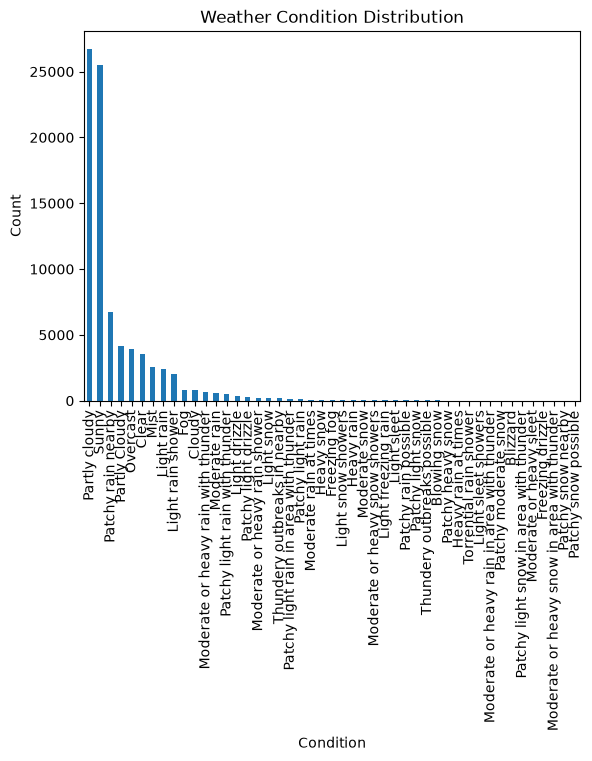

In [90]:
#I found the table above hard to read, I wanted to see what was comon and what wasn't. Tried plotting it instead
weather_df['condition_text'].value_counts().plot(kind='bar')
plt.title('Weather Condition Distribution')
plt.xlabel('Condition')
plt.ylabel('Count')

In [91]:
#I wanted to store the top 10 most common weather types to keep in mind for designing environments
conditions = weather_df['condition_text'].value_counts()
#list(conditions[0:10].index)
conditions_list = list(conditions.head(10).index)
conditions_list

['Partly cloudy',
 'Sunny',
 'Patchy rain nearby',
 'Partly Cloudy',
 'Overcast',
 'Clear',
 'Mist',
 'Light rain',
 'Light rain shower',
 'Fog']

In [92]:
#pick one of the top 10 conditions to generate a scene with
import random
random.choice(conditions_list)

'Mist'

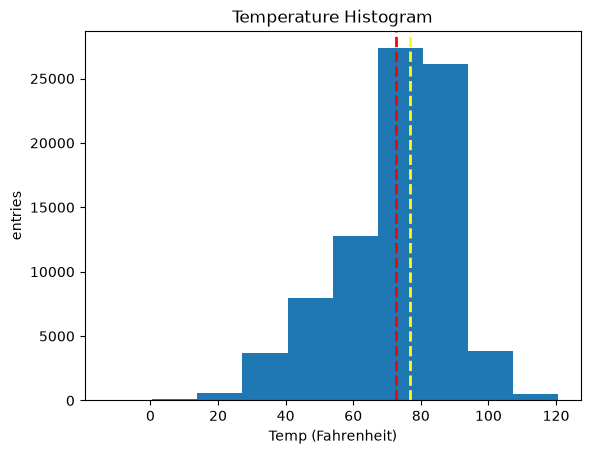

In [93]:
#I felt like that was a little too easy... let's see if there is an insight between temperature and weather type.
#first... let's just get a sense of the temp distrubution overall

plt.hist(weather_df.temperature_fahrenheit)
plt.xlabel("Temp (Fahrenheit)")
plt.ylabel('entries')
plt.title("Temperature Histogram")
plt.axvline(weather_df.temperature_fahrenheit.mean(), color="red", linestyle="dashed", linewidth=2)
plt.axvline(weather_df.temperature_fahrenheit.median(), color="yellow", linestyle="dashed", linewidth=2)

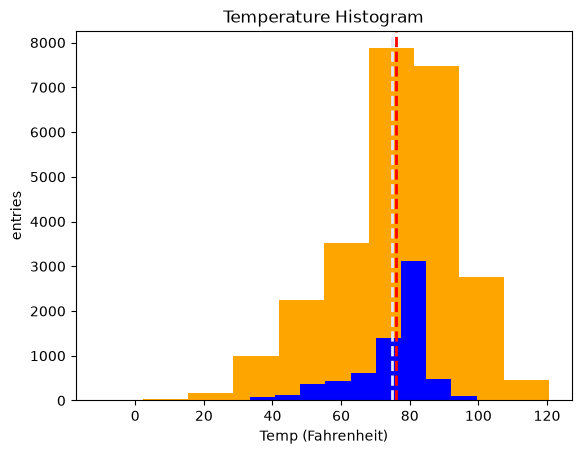

In [109]:
#See the temperature distribution when it rains compared to when it is sunny
condition_grouping = weather_df.groupby('condition_text')
sunny_df = condition_grouping.get_group('Sunny')
rain_df= condition_grouping.get_group('Patchy rain nearby')

plt.hist(sunny_df.temperature_fahrenheit, color="orange")
plt.hist(rain_df.temperature_fahrenheit, color="blue")

plt.xlabel("Temp (Fahrenheit)")
plt.ylabel('entries')
plt.title("Temperature Histogram")

plt.axvline(sunny_df.temperature_fahrenheit.mean(), color="red", linestyle="dashed", linewidth=2)
plt.axvline(rain_df.temperature_fahrenheit.mean(), color="lavender", linestyle="dashed", linewidth=2)

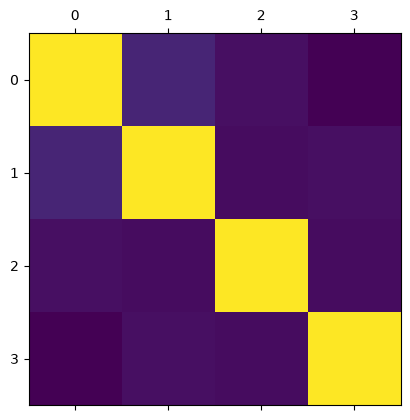

In [126]:
#curious about if there are any correlations between float entries... temp & wind? What about moon or air quality
weather_values = weather_df[['wind_mph', 'temperature_fahrenheit', 'moon_illumination', 'air_quality_PM2.5']]
corr_weather = weather_values.corr()
corr_weather
plt.matshow(weather_values.corr())

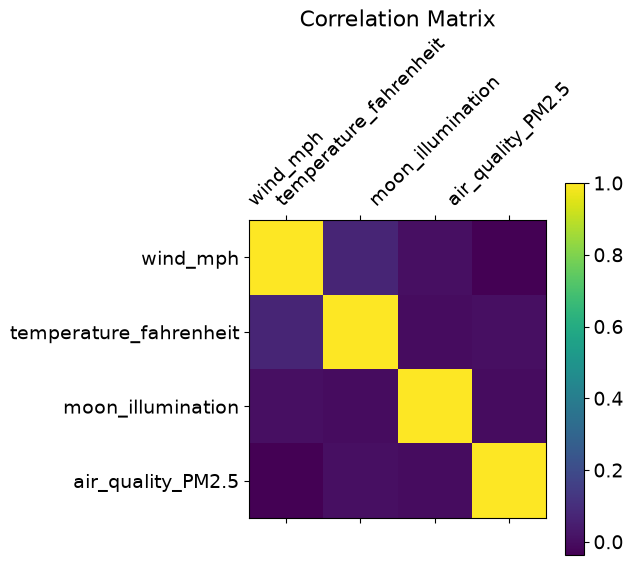

In [127]:
#add some labels to help make sense of this!
plt.matshow(weather_values.corr())
plt.xticks(range(weather_values.select_dtypes(['number']).shape[1]), weather_values.select_dtypes(['number']).columns, fontsize=14, rotation=45)
plt.yticks(range(weather_values.select_dtypes(['number']).shape[1]), weather_values.select_dtypes(['number']).columns, fontsize=14)
cb = plt.colorbar()
cb.ax.tick_params(labelsize=14)
plt.title('Correlation Matrix', fontsize=16);
plt.show()